In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import tensorflow_hub as hub
import PIL.Image as Image
import matplotlib.pyplot as plt

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


<br><br>

---
#<font color='SeaGreen'>Chapter 1. If you don't have the model saved on disk yet, then we will create the model, train it and save it.</font>

>>*If you already have a model (saved_model_CIFAR10.zip) on disk then go to the next chapter*





###<font color='SeaGreen'>Step 1. Download and prepare the CIFAR10 dataset</font>

In [2]:
''' 2026-10-22
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()
train_images, test_images = train_images / 255.0, test_images / 255.0
'''

' 2026-10-22\n(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()\ntrain_images, test_images = train_images / 255.0, test_images / 255.0\n'

In [3]:
!pip install -q kagglehub
import os, glob, kagglehub
import numpy as np
from PIL import Image

path = kagglehub.dataset_download("puneet6060/intel-image-classification")

# Randame aplankus seg_train ir seg_test (gilesnį, kuriame yra klasių aplankai)
train_dir = sorted(glob.glob(path + "/**/seg_train", recursive=True), key=len)[-1]
test_dir  = sorted(glob.glob(path + "/**/seg_test",  recursive=True), key=len)[-1]

class_names = sorted(d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d)))
print(class_names)

def load_folder(folder, size=(32, 32)):
    images, labels = [], []
    for label, cls in enumerate(class_names):
        for f in glob.glob(os.path.join(folder, cls, "*")):
            img = Image.open(f).convert("RGB").resize(size)
            images.append(np.array(img))
            labels.append(label)
    images = np.stack(images).astype("float32") / 255.0     # normalizavimas jau čia
    labels = np.array(labels).reshape(-1, 1)
    idx = np.random.permutation(len(images))                # sumaišome
    return images[idx], labels[idx]

train_images, train_labels = load_folder(train_dir)
test_images,  test_labels  = load_folder(test_dir)
print(train_images.shape, test_images.shape)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
(14034, 32, 32, 3) (3000, 32, 32, 3)


In [4]:

feature_extractor_model = "https://tfhub.dev/google/imagenet/efficientnet_v2_imagenet21k_b1/feature_vector/2"
IMAGE_SHAPE = (240, 240)
feature_extractor_layer = hub.KerasLayer( feature_extractor_model, input_shape=(IMAGE_SHAPE[0], IMAGE_SHAPE[1], 3),  trainable=False)


In [5]:
!pip install -q tf_keras

In [6]:
import tf_keras

num_classes = len(class_names)

resize = tf_keras.layers.Resizing(IMAGE_SHAPE[0], IMAGE_SHAPE[1])

model = tf_keras.Sequential([  resize,  feature_extractor_layer,  tf_keras.layers.Dense(num_classes) ])

model.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),  metrics=['accuracy'])

In [7]:
'''
num_classes = len(class_names)

resize = tf.keras.layers.Resizing(IMAGE_SHAPE[0], IMAGE_SHAPE[1])

model = tf.keras.Sequential([
  resize,
  feature_extractor_layer,
  tf.keras.layers.Dense(num_classes)
])

model.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),  metrics=['accuracy'])
'''

"\nnum_classes = len(class_names)\n\nresize = tf.keras.layers.Resizing(IMAGE_SHAPE[0], IMAGE_SHAPE[1])\n\nmodel = tf.keras.Sequential([\n  resize,\n  feature_extractor_layer,\n  tf.keras.layers.Dense(num_classes)\n])\n\nmodel.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),  metrics=['accuracy'])\n"

In [8]:
model.build(input_shape=(None , 32, 32, 3))
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resizing (Resizing)         (None, 240, 240, 3)       0         
                                                                 
 keras_layer (KerasLayer)    (None, 1280)              6931124   
                                                                 
 dense (Dense)               (None, 6)                 7686      
                                                                 
Total params: 6938810 (26.47 MB)
Trainable params: 7686 (30.02 KB)
Non-trainable params: 6931124 (26.44 MB)
_________________________________________________________________


## model.fit

In [9]:
history = model.fit(train_images, train_labels, epochs=3, validation_data=(test_images, test_labels))

Epoch 1/3
439/439 [==============================] - 61s 84ms/step - loss: 0.4443 - accuracy: 0.8399 - val_loss: 0.3240 - val_accuracy: 0.8820
Epoch 2/3
439/439 [==============================] - 36s 83ms/step - loss: 0.3022 - accuracy: 0.8896 - val_loss: 0.3034 - val_accuracy: 0.8907
Epoch 3/3
439/439 [==============================] - 37s 84ms/step - loss: 0.2711 - accuracy: 0.8990 - val_loss: 0.2997 - val_accuracy: 0.8927


In [10]:
test_loss, test_acc = model.evaluate(test_images ,  test_labels  )
print(test_acc)

94/94 [==============================] - 7s 70ms/step - loss: 0.2997 - accuracy: 0.8927
0.8926666378974915


In [11]:
export_path = "saved_model_CIFAR10"
model.save(export_path)
!zip -r saved_model_CIFAR10.zip saved_model_CIFAR10


  adding: saved_model_CIFAR10/ (stored 0%)
  adding: saved_model_CIFAR10/variables/ (stored 0%)
  adding: saved_model_CIFAR10/variables/variables.data-00000-of-00001 (deflated 8%)
  adding: saved_model_CIFAR10/variables/variables.index (deflated 80%)
  adding: saved_model_CIFAR10/keras_metadata.pb (deflated 81%)
  adding: saved_model_CIFAR10/saved_model.pb (deflated 91%)
  adding: saved_model_CIFAR10/assets/ (stored 0%)
  adding: saved_model_CIFAR10/fingerprint.pb (stored 0%)


<br><br>

---
###<font color='SeaGreen'>Let's plot the first 100 images </font>


In [12]:
'''img = train_images[4-1]
img = tf.expand_dims(img, axis=0)

result = model.predict(img)

predicted_class = tf.math.argmax(result[0], axis=-1)
predicted_class_name = class_names[predicted_class]
predicted_class_name'''

'img = train_images[4-1]\nimg = tf.expand_dims(img, axis=0)\n\nresult = model.predict(img)\n\npredicted_class = tf.math.argmax(result[0], axis=-1)\npredicted_class_name = class_names[predicted_class]\npredicted_class_name'

In [13]:
%%capture

predicted_class_name = [''] * 100

for i in range(100):
    img = tf.expand_dims(test_images[i], axis=0)
    result = model.predict(img);

    predicted_class = tf.math.argmax(result[0], axis=-1)
    predicted_class_name[i] = class_names[predicted_class]



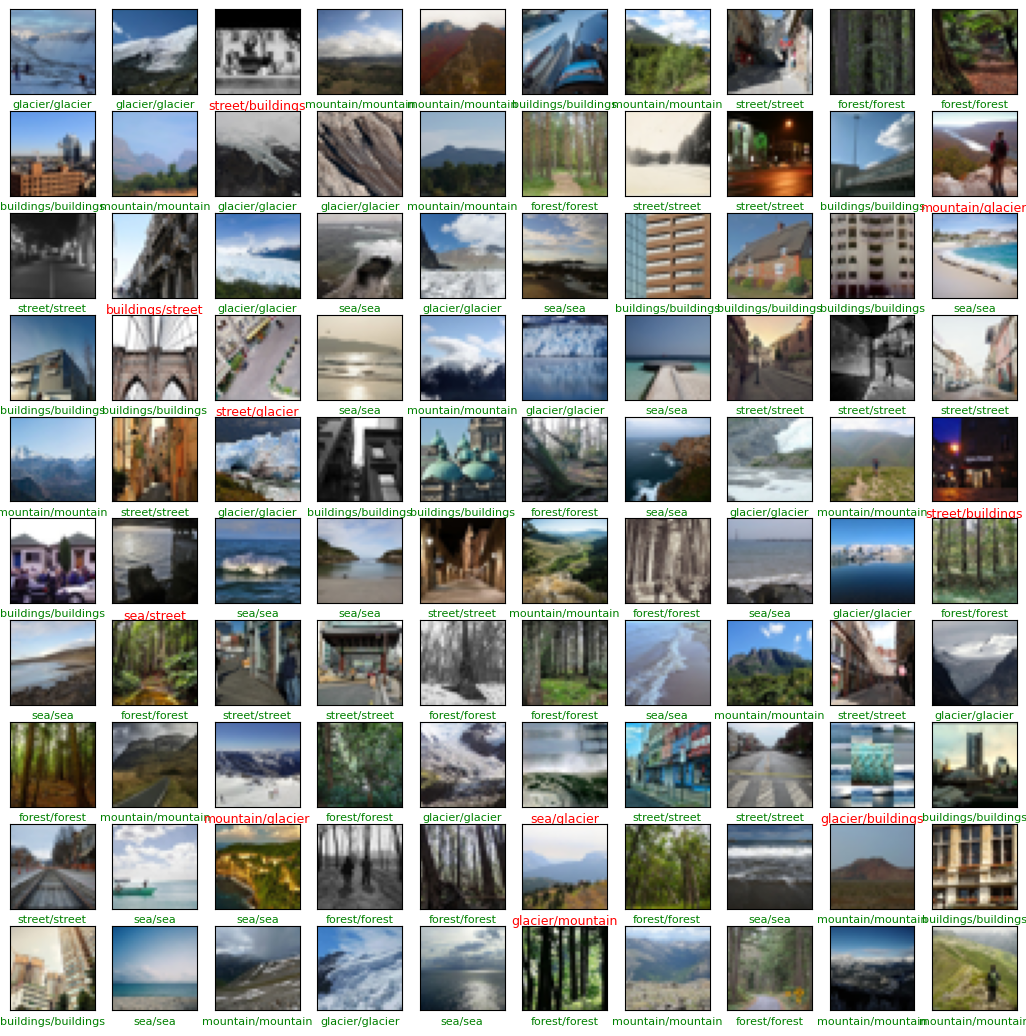

In [14]:

plt.figure(figsize=(13,13))
for i in range(100):
    plt.subplot(10,10,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(test_images[i])

    if class_names[test_labels[i][0]]==predicted_class_name[i]:
      plt.xlabel(class_names[test_labels[i][0]]+'/'+predicted_class_name[i], color='green', fontsize=8)
    else:
      plt.xlabel(class_names[test_labels[i][0]]+'/'+predicted_class_name[i], color='red', fontsize=9)

plt.show()


<br><br><br><br>

---
#<font color='SeaGreen'>Chapter 2. Use data augmentation</font>



In [15]:
''' 2026-10-22
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()
train_images, test_images = train_images / 255.0, test_images / 255.0
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
'''

" 2026-10-22\n(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()\ntrain_images, test_images = train_images / 255.0, test_images / 255.0\nclass_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']\n"

In [16]:
export_path = "saved_model_CIFAR10"
!unzip saved_model_CIFAR10.zip


Archive:  saved_model_CIFAR10.zip
replace saved_model_CIFAR10/variables/variables.data-00000-of-00001? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
  inflating: saved_model_CIFAR10/variables/variables.data-00000-of-00001  
  inflating: saved_model_CIFAR10/variables/variables.index  
  inflating: saved_model_CIFAR10/keras_metadata.pb  
  inflating: saved_model_CIFAR10/saved_model.pb  
 extracting: saved_model_CIFAR10/fingerprint.pb  


In [17]:
#model = tf.keras.models.load_model(export_path)
model = tf_keras.models.load_model(export_path)

!rm -r saved_model_CIFAR10
!rm saved_model_CIFAR10.zip

In [18]:
for layer in model.layers:
    print(f"Layer: {layer.name}, Trainable: {layer.trainable}")

Layer: resizing, Trainable: True
Layer: keras_layer, Trainable: False
Layer: dense, Trainable: True


In [19]:
optimizer = model.optimizer
print(model.optimizer.lr)
new_lr = optimizer.lr * 0.1
optimizer.lr.assign(new_lr)
print(model.optimizer.lr)

<tf.Variable 'learning_rate:0' shape=() dtype=float32, numpy=0.0010000000474974513>
<tf.Variable 'learning_rate:0' shape=() dtype=float32, numpy=0.00010000000474974513>


In [20]:
model.trainable = True
for layer in model.layers:
    print(f"Layer: {layer.name}, Trainable: {layer.trainable}")

Layer: resizing, Trainable: True
Layer: keras_layer, Trainable: True
Layer: dense, Trainable: True


In [21]:
data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomFlip('horizontal'),
  tf.keras.layers.RandomRotation(0.1),
  tf.keras.layers.RandomBrightness(factor=0.1, value_range=(0, 1)),
  #tf.keras.layers.RandomHeight(factor=0.1),
  #tf.keras.layers.RandomWidth(factor=0.1),
  ##tf.keras.layers.RandomContrast(factor=0.1),
  tf.keras.layers.RandomTranslation(0.1, 0.1),
  #tf.keras.layers.RandomZoom(0.1, 0.1),
])

In [22]:
for i in range(3):
  print(f"--- Iteration {i+1}/10 ---")
  # Apply dynamic augmentation on the already loaded training set
  augmented_train_images = data_augmentation(train_images)

  # Train the model
  history = model.fit(
      augmented_train_images,
      train_labels,
      epochs=1,
      batch_size=64,
      validation_data=(test_images, test_labels)
  )

--- Iteration 1/10 ---
220/220 [==============================] - 45s 161ms/step - loss: 0.6013 - accuracy: 0.7765 - val_loss: 0.3092 - val_accuracy: 0.8860
--- Iteration 2/10 ---
220/220 [==============================] - 34s 155ms/step - loss: 0.5560 - accuracy: 0.7958 - val_loss: 0.3071 - val_accuracy: 0.8857
--- Iteration 3/10 ---
220/220 [==============================] - 34s 153ms/step - loss: 0.5336 - accuracy: 0.8048 - val_loss: 0.3070 - val_accuracy: 0.8860


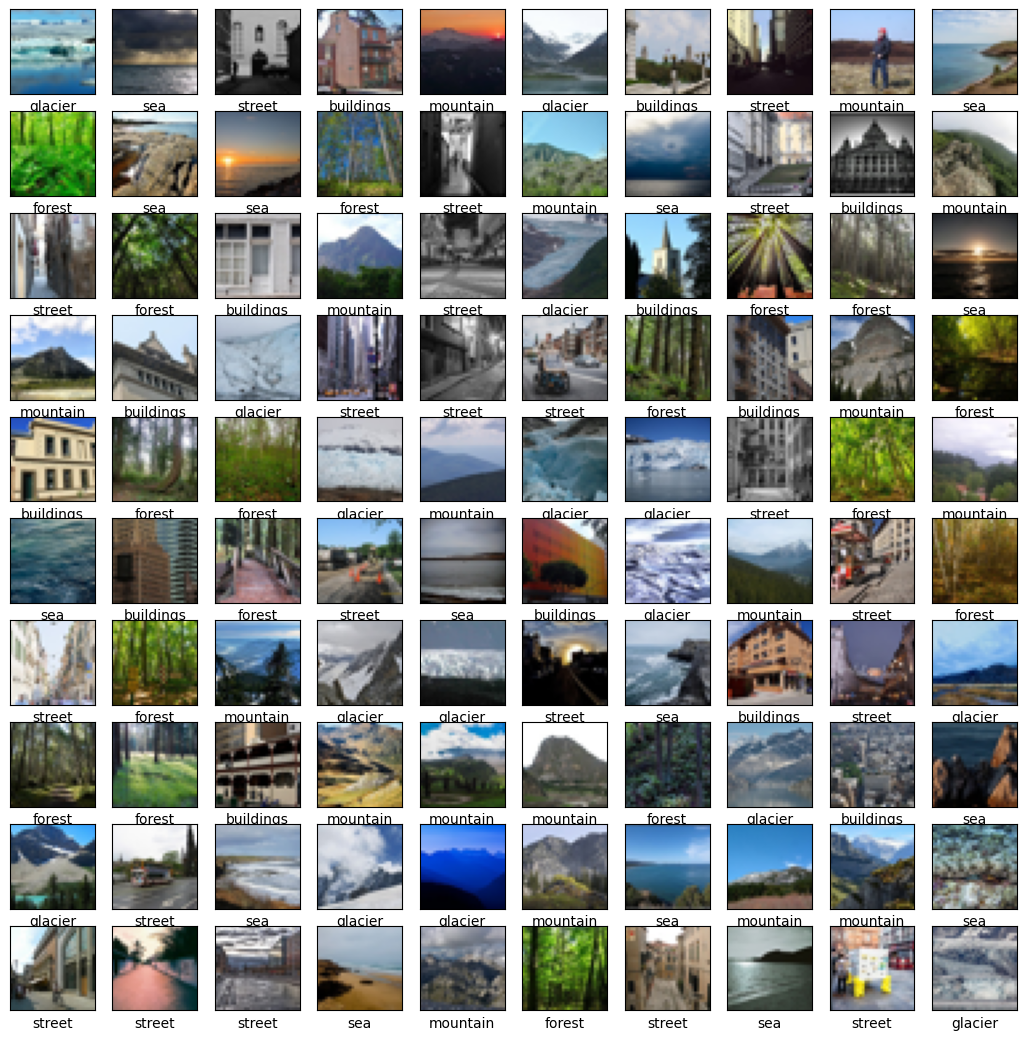

In [23]:

plt.figure(figsize=(13,13))
for i in range(100):
    plt.subplot(10,10,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i][0]])
plt.show()

In [24]:
 model.layers[2].trainable

True

In [25]:
for i, weights in enumerate(model.weights):
    print(i, weights.name)


0 efficientnetv2-b1/blocks_0/conv2d/kernel:0
1 efficientnetv2-b1/blocks_0/tpu_batch_normalization/gamma:0
2 efficientnetv2-b1/blocks_0/tpu_batch_normalization/beta:0
3 efficientnetv2-b1/blocks_1/conv2d/kernel:0
4 efficientnetv2-b1/blocks_1/tpu_batch_normalization/gamma:0
5 efficientnetv2-b1/blocks_1/tpu_batch_normalization/beta:0
6 efficientnetv2-b1/blocks_2/conv2d/kernel:0
7 efficientnetv2-b1/blocks_2/tpu_batch_normalization/gamma:0
8 efficientnetv2-b1/blocks_2/tpu_batch_normalization/beta:0
9 efficientnetv2-b1/blocks_2/conv2d_1/kernel:0
10 efficientnetv2-b1/blocks_2/tpu_batch_normalization_1/gamma:0
11 efficientnetv2-b1/blocks_2/tpu_batch_normalization_1/beta:0
12 efficientnetv2-b1/blocks_3/conv2d/kernel:0
13 efficientnetv2-b1/blocks_3/tpu_batch_normalization/gamma:0
14 efficientnetv2-b1/blocks_3/tpu_batch_normalization/beta:0
15 efficientnetv2-b1/blocks_3/conv2d_1/kernel:0
16 efficientnetv2-b1/blocks_3/tpu_batch_normalization_1/gamma:0
17 efficientnetv2-b1/blocks_3/tpu_batch_normali

In [26]:
print("Number of layers in the base model: ", len( model.layers))

Number of layers in the base model:  3
